<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Random_Forest_vs_Decision_Tree_Breast_Cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest vs. Árbol de Decisión
## Laboratorio de Códigos · Demostración con Breast Cancer Wisconsin

Este notebook compara ambos modelos con la misma división de entrenamiento/prueba. Incluye tablas de métricas, fronteras de decisión en dos variables, visualización del árbol, evolución del rendimiento al aumentar los árboles, importancia de características, matrices de confusión y análisis de profundidad.

**Importante:** es una demostración educativa con un dataset público de investigación. No debe usarse para diagnóstico médico. Las fronteras en 2D usan solo dos variables para poder dibujarlas; las métricas principales usan las 30 características.

## 1. Instalar/importar librerías

In [16]:
# En Google Colab, normalmente estas librerías ya están disponibles.
%pip -q install scikit-learn pandas matplotlib seaborn

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.inspection import permutation_importance

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

print("Librerías listas.")

Librerías listas.


## 2. Cargar el dataset y explorar sus características

In [18]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target  # 0 = malignant, 1 = benign en este dataset

# Para que las gráficas y las métricas sean intuitivas, recodificamos:
# 1 = maligno, 0 = benigno. Positivo significa "maligno".
y = (data.target == 0).astype(int)
class_names = ["Benigno", "Maligno"]

print(f"Casos: {X.shape[0]}")
print(f"Características: {X.shape[1]}")
print(pd.Series(y).map({0:"Benigno", 1:"Maligno"}).
      value_counts().rename("casos"))

display(X.head())
display(X.describe().T.head(10))

Casos: 569
Características: 30
target
Benigno    357
Maligno    212
Name: casos, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 3. División de entrenamiento y prueba

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

print(f"Entrenamiento: {len(X_train)} casos")
print(f"Prueba: {len(X_test)} casos")
print("\nProporción de malignos:")
print(f"Entrenamiento: {y_train.mean():.3f} | Prueba: {y_test.mean():.3f}")

Entrenamiento: 426 casos
Prueba: 143 casos

Proporción de malignos:
Entrenamiento: 0.373 | Prueba: 0.371


## 4. Entrenar ambos modelos

In [20]:
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=4,
    random_state=SEED
)

forest = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    n_jobs=-1,
    random_state=SEED
)

tree.fit(X_train, y_train)
forest.fit(X_train, y_train)

print("Modelos entrenados.")

Modelos entrenados.


## 5. Tabla comparativa de métricas

In [21]:
def metric_row(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Modelo": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precisión (maligno)": precision_score(y_eval, pred, zero_division=0),
        "Recall/Sensibilidad (maligno)": recall_score(y_eval, pred, zero_division=0),
        "F1 (maligno)": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob),
    }

metrics = pd.DataFrame([
    metric_row("Árbol de Decisión", tree, X_test, y_test),
    metric_row("Random Forest", forest, X_test, y_test)
]).set_index("Modelo")

display(metrics.style.format("{:.3f}").highlight_max(axis=0, color="#d7f5df"))

print("Reporte — Árbol de Decisión")
print(classification_report(y_test, tree.predict(X_test),
                            target_names=class_names, zero_division=0))
print("Reporte — Random Forest")
print(classification_report(y_test, forest.predict(X_test),
                            target_names=class_names, zero_division=0))

,Accuracy,Precisión (maligno),Recall/Sensibilidad (maligno),F1 (maligno),ROC-AUC
Modelo,,,,,
Árbol de Decisión,0.881,0.950,0.717,0.817,0.965
Random Forest,0.965,1.000,0.906,0.950,0.996


Reporte — Árbol de Decisión
              precision    recall  f1-score   support

     Benigno       0.85      0.98      0.91        90
     Maligno       0.95      0.72      0.82        53

    accuracy                           0.88       143
   macro avg       0.90      0.85      0.86       143
weighted avg       0.89      0.88      0.88       143

Reporte — Random Forest
              precision    recall  f1-score   support

     Benigno       0.95      1.00      0.97        90
     Maligno       1.00      0.91      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



## 6. Gráfica comparativa de métricas

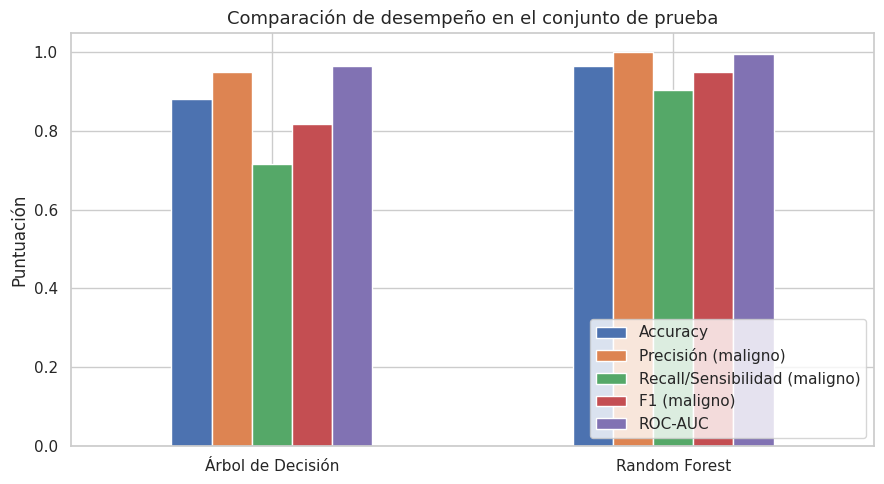

In [22]:
metrics.plot(kind="bar", ylim=(0, 1.05), rot=0)
plt.title("Comparación de desempeño en el conjunto de prueba")
plt.ylabel("Puntuación")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Matrices de confusión

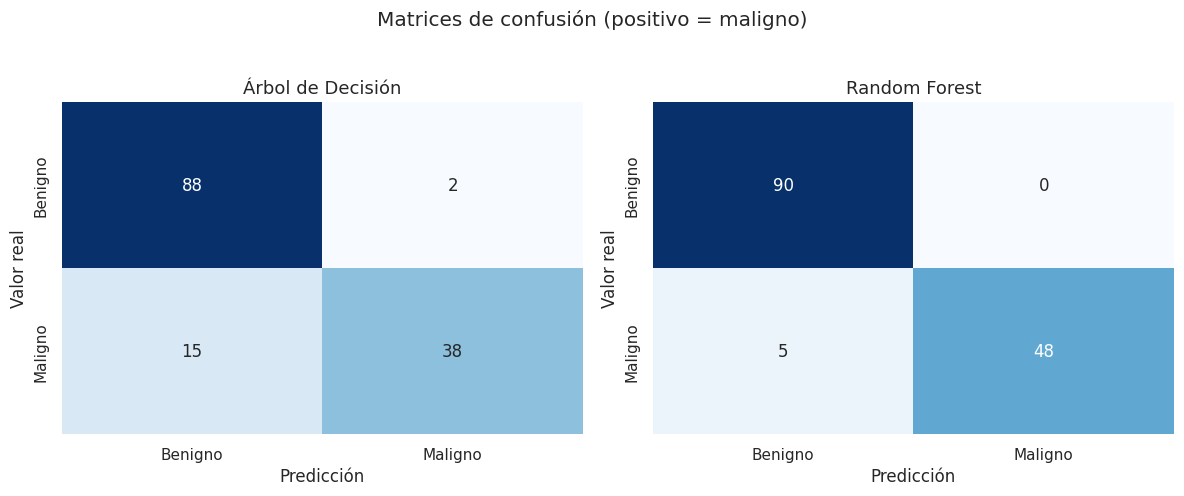

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, name, model in zip(axes, ["Árbol de Decisión", "Random Forest"], [tree, forest]):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
plt.suptitle("Matrices de confusión (positivo = maligno)", y=1.03)
plt.tight_layout()
plt.show()

## 8. Fronteras de decisión en dos características
Seleccionamos dos variables con señal útil para la demostración. Los modelos se vuelven a entrenar usando **solo esas dos variables** para que la frontera sea realmente bidimensional. Estas gráficas no representan los modelos de 30 variables usados en la tabla de métricas.

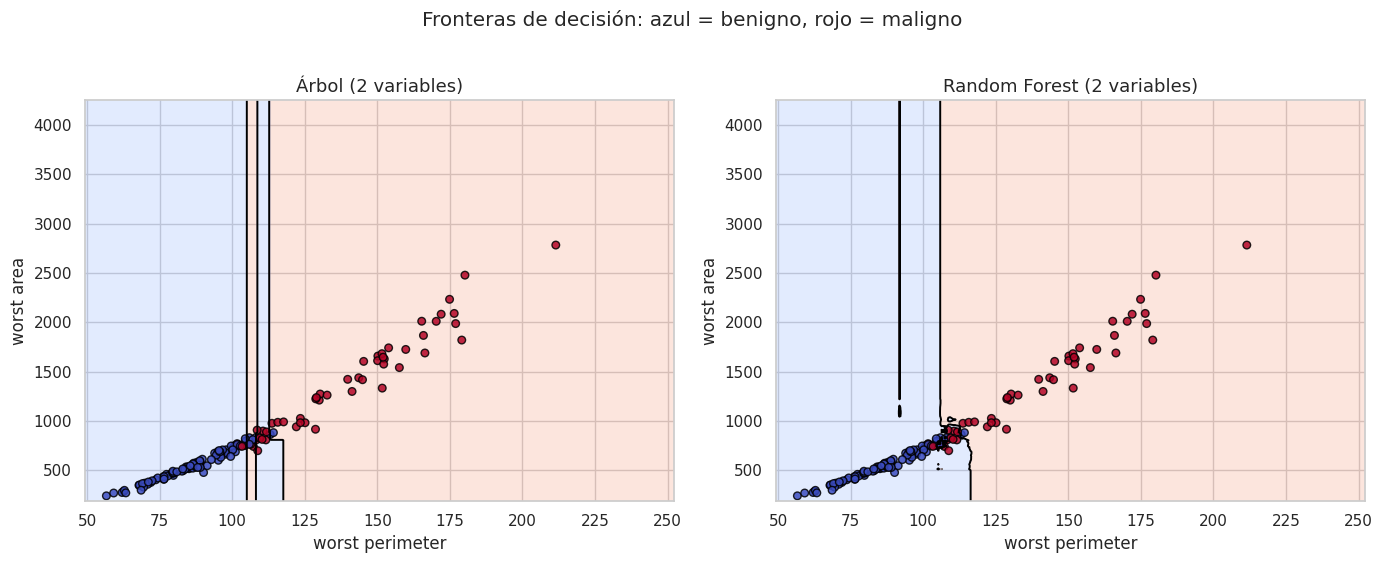

In [24]:
feature_x = "worst perimeter"
feature_y = "worst area"
X2 = X[[feature_x, feature_y]]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=SEED, stratify=y
)

tree2 = DecisionTreeClassifier(max_depth=4, min_samples_leaf=4, random_state=SEED)
forest2 = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", min_samples_leaf=2,
    n_jobs=-1, random_state=SEED
)
tree2.fit(X2_train, y2_train)
forest2.fit(X2_train, y2_train)

x_min, x_max = X2[feature_x].min() - 1, X2[feature_x].max() + 1
y_min, y_max = X2[feature_y].min() - 0.03, X2[feature_y].max() + 0.03
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 350),
                     np.linspace(y_min, y_max, 350))
grid = pd.DataFrame({feature_x: xx.ravel(), feature_y: yy.ravel()})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name, model in zip(axes, ["Árbol (2 variables)", "Random Forest (2 variables)"],
                           [tree2, forest2]):
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5], cmap="coolwarm")
    ax.contour(xx, yy, model.predict_proba(grid)[:, 1].reshape(xx.shape),
               levels=[0.5], colors="black", linewidths=1.4)
    ax.scatter(X2_test[feature_x], X2_test[feature_y], c=y2_test,
               cmap="coolwarm", edgecolor="black", s=30, alpha=0.85)
    ax.set_title(name)
    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
plt.suptitle("Fronteras de decisión: azul = benigno, rojo = maligno", y=1.02)
plt.tight_layout()
plt.show()

## 9. Cómo se configura y trabaja el Árbol de Decisión

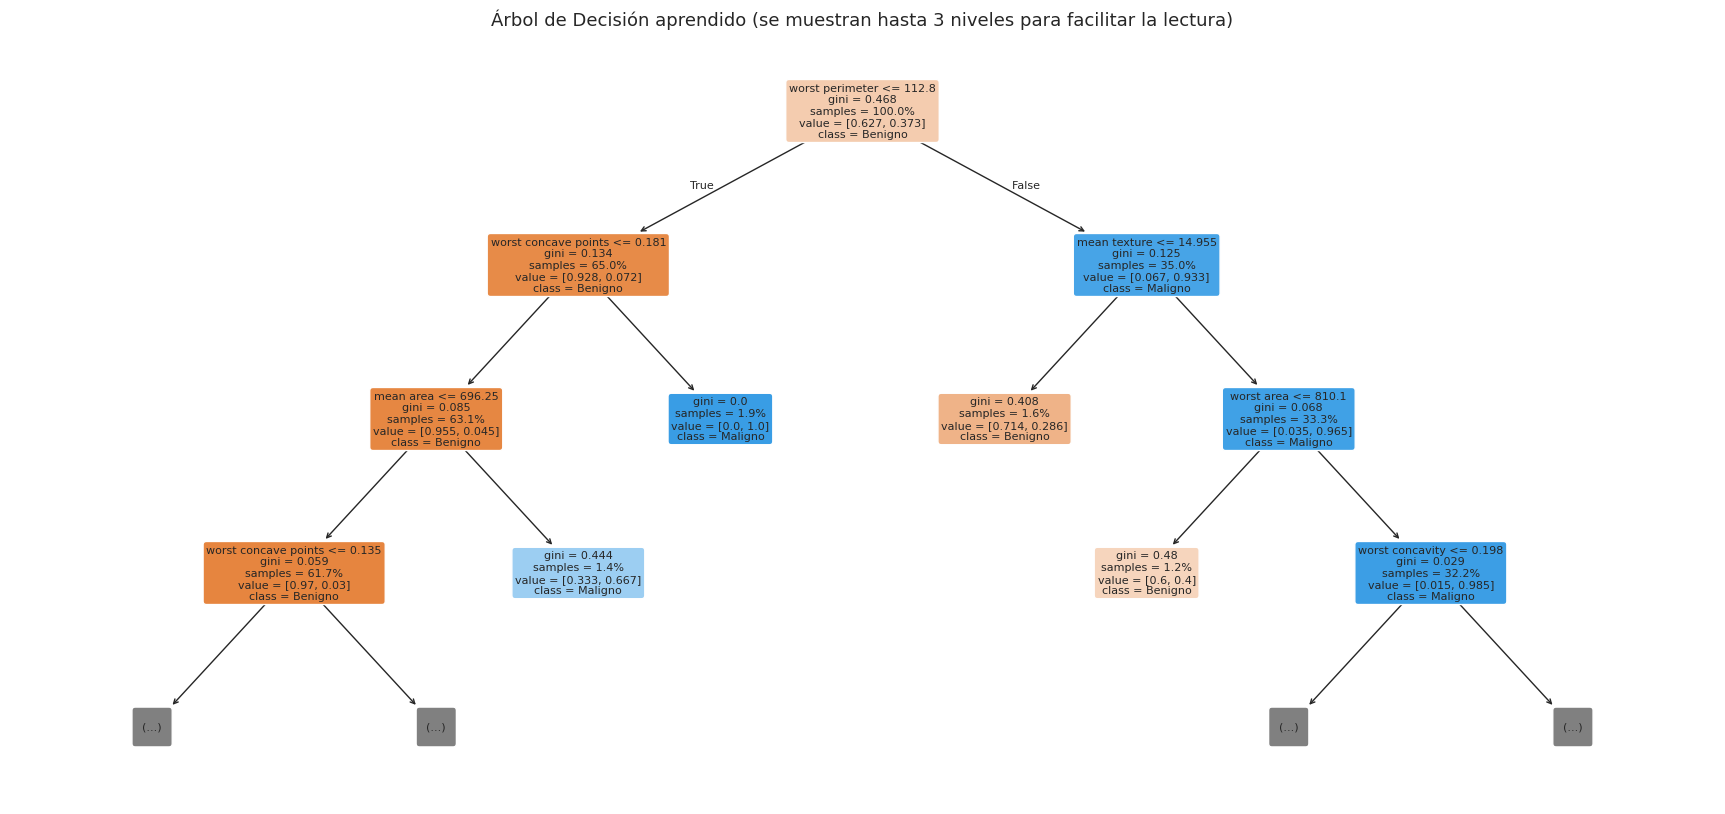

Profundidad real del árbol: 4
Número de hojas: 8


In [25]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=class_names,
    filled=True,
    rounded=True,
    impurity=True,
    proportion=True,
    max_depth=3,  # solo limita la visualización; el modelo entrenado tiene profundidad máxima 4
    fontsize=8,
    ax=ax
)
plt.title("Árbol de Decisión aprendido (se muestran hasta 3 niveles para facilitar la lectura)")
plt.show()

print("Profundidad real del árbol:", tree.get_depth())
print("Número de hojas:", tree.get_n_leaves())

## 10. Evolución de Random Forest al aumentar el número de árboles
Entrenamos bosques de distintos tamaños y medimos desempeño en prueba. La curva puede fluctuar; no tiene por qué mejorar estrictamente en cada punto.

,Árboles,Accuracy,F1 maligno,Recall maligno
0,1,0.923,0.889,0.830
1,5,0.965,0.950,0.906
2,10,0.951,0.929,0.868
3,20,0.965,0.950,0.906
4,40,0.958,0.941,0.906
5,60,0.972,0.961,0.925
6,100,0.965,0.950,0.906
7,150,0.965,0.950,0.906
8,200,0.965,0.950,0.906
9,300,0.965,0.950,0.906


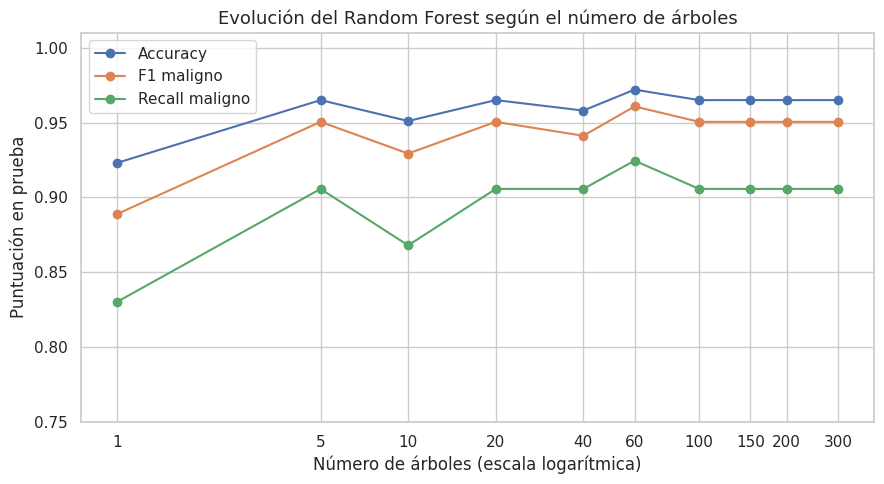

In [26]:
n_values = [1, 5, 10, 20, 40, 60, 100, 150, 200, 300]
evolution = []
for n in n_values:
    rf = RandomForestClassifier(
        n_estimators=n, max_features="sqrt", min_samples_leaf=2,
        n_jobs=-1, random_state=SEED
    )
    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)
    evolution.append({
        "Árboles": n,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 maligno": f1_score(y_test, pred, zero_division=0),
        "Recall maligno": recall_score(y_test, pred, zero_division=0)
    })

evolution_df = pd.DataFrame(evolution)
display(evolution_df.style.format({c:"{:.3f}" for c in ["Accuracy","F1 maligno","Recall maligno"]}))

plt.figure(figsize=(9, 5))
for col in ["Accuracy", "F1 maligno", "Recall maligno"]:
    plt.plot(evolution_df["Árboles"], evolution_df[col], marker="o", label=col)
plt.xscale("log")
plt.xticks(n_values, [str(n) for n in n_values])
plt.ylim(0.75, 1.01)
plt.xlabel("Número de árboles (escala logarítmica)")
plt.ylabel("Puntuación en prueba")
plt.title("Evolución del Random Forest según el número de árboles")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Efecto de la profundidad en el Árbol de Decisión

,Profundidad,Accuracy entrenamiento,Accuracy prueba,F1 prueba,Hojas
0,1,0.930,0.888,0.830,2
1,2,0.955,0.895,0.839,4
2,3,0.967,0.888,0.830,7
3,4,0.979,0.895,0.839,11
4,5,0.988,0.944,0.920,14
5,6,0.995,0.937,0.911,18
6,7,0.998,0.951,0.932,20
7,8,1.000,0.958,0.941,21
8,9,1.000,0.958,0.941,21
9,10,1.000,0.958,0.941,21


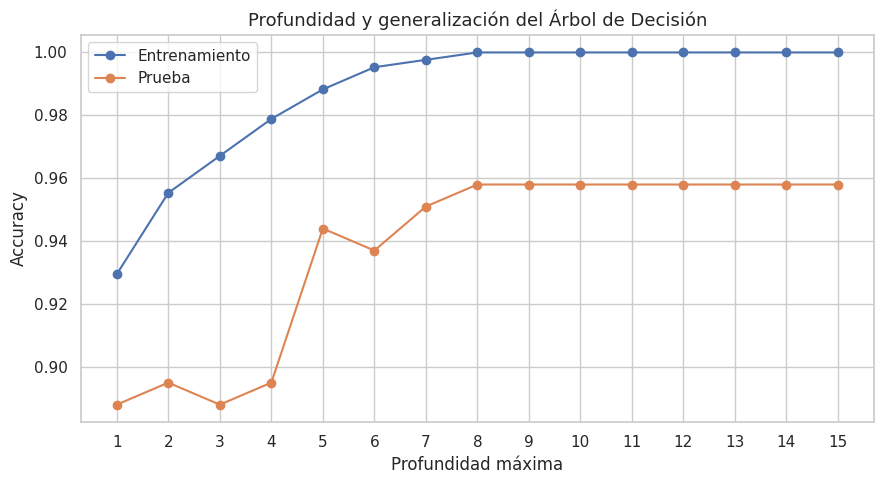

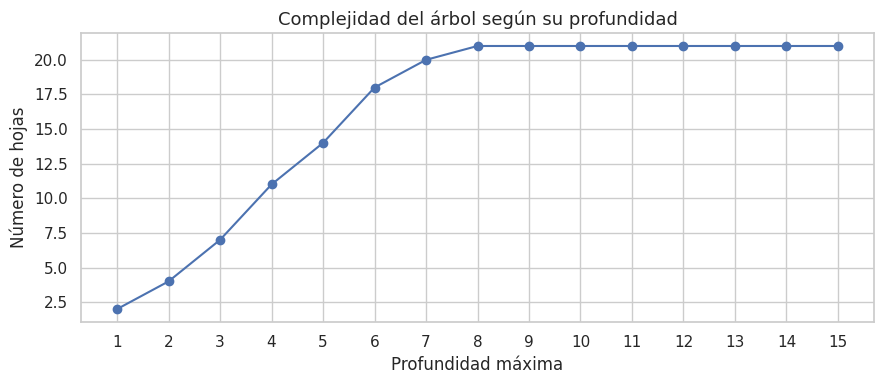

In [27]:
depth_values = list(range(1, 16))
depth_rows = []
for depth in depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    model.fit(X_train, y_train)
    depth_rows.append({
        "Profundidad": depth,
        "Accuracy entrenamiento": accuracy_score(y_train, model.predict(X_train)),
        "Accuracy prueba": accuracy_score(y_test, model.predict(X_test)),
        "F1 prueba": f1_score(y_test, model.predict(X_test), zero_division=0),
        "Hojas": model.get_n_leaves()
    })

depth_df = pd.DataFrame(depth_rows)
display(depth_df.style.format({
    "Accuracy entrenamiento":"{:.3f}", "Accuracy prueba":"{:.3f}", "F1 prueba":"{:.3f}"
}))

plt.figure(figsize=(9, 5))
plt.plot(depth_df["Profundidad"], depth_df["Accuracy entrenamiento"], marker="o", label="Entrenamiento")
plt.plot(depth_df["Profundidad"], depth_df["Accuracy prueba"], marker="o", label="Prueba")
plt.xlabel("Profundidad máxima")
plt.ylabel("Accuracy")
plt.title("Profundidad y generalización del Árbol de Decisión")
plt.xticks(depth_values)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(depth_df["Profundidad"], depth_df["Hojas"], marker="o")
plt.xlabel("Profundidad máxima")
plt.ylabel("Número de hojas")
plt.title("Complejidad del árbol según su profundidad")
plt.xticks(depth_values)
plt.tight_layout()
plt.show()

## 12. Importancia de las características

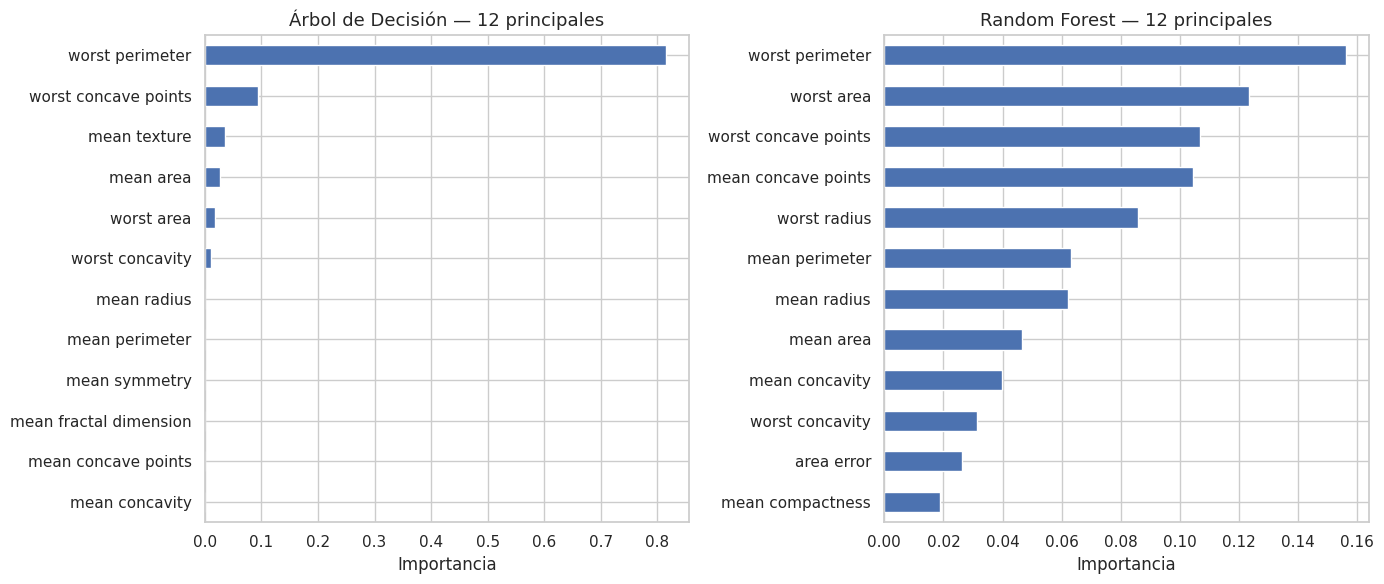

In [28]:
imp_tree = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
imp_forest = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp_tree.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Árbol de Decisión — 12 principales")
axes[0].set_xlabel("Importancia")
imp_forest.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Random Forest — 12 principales")
axes[1].set_xlabel("Importancia")
plt.tight_layout()
plt.show()

## 13. Comparación de estabilidad entre árboles individuales y bosque
El bosque contiene muchos árboles; las predicciones de algunos árboles individuales pueden diferir. Esta visualización muestra la proporción de árboles del bosque que vota por maligno para cada caso de prueba.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: U

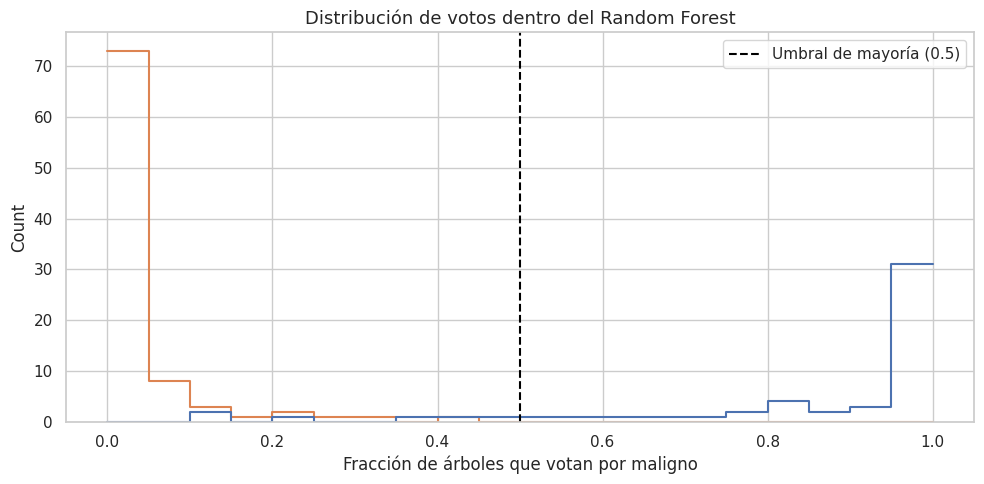

,Proporción de votos por maligno,Clase real,Predicción final
0,0.925,Maligno,Maligno
1,0.020,Benigno,Benigno
2,0.905,Maligno,Maligno
3,0.005,Benigno,Benigno
4,0.335,Benigno,Benigno
5,0.005,Benigno,Benigno
6,0.025,Benigno,Benigno
7,0.000,Benigno,Benigno
8,0.005,Benigno,Benigno
9,0.270,Benigno,Benigno


In [29]:
# Cada árbol del bosque produce una predicción individual.
tree_votes = np.vstack([est.predict(X_test) for est in forest.estimators_])
malignant_vote_share = tree_votes.mean(axis=0)

vote_df = pd.DataFrame({
    "Proporción de votos por maligno": malignant_vote_share,
    "Clase real": np.where(y_test.to_numpy() == 1, "Maligno", "Benigno"),
    "Predicción final": np.where(forest.predict(X_test) == 1, "Maligno", "Benigno")
})

plt.figure(figsize=(10, 5))
sns.histplot(data=vote_df, x="Proporción de votos por maligno", hue="Clase real",
             bins=20, stat="count", common_norm=False, element="step", fill=False)
plt.axvline(0.5, color="black", linestyle="--", label="Umbral de mayoría (0.5)")
plt.xlabel("Fracción de árboles que votan por maligno")
plt.title("Distribución de votos dentro del Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

display(vote_df.head(12))

## 14. Resumen automático y ventajas/desventajas

In [30]:
summary = pd.DataFrame([
    {
        "Modelo": "Árbol de Decisión",
        "Ventajas": "Fácil de explicar; reglas visibles; entrenamiento rápido; poca preparación de datos.",
        "Desventajas": "Puede sobreajustar; alta variación ante cambios en los datos; fronteras escalonadas."
    },
    {
        "Modelo": "Random Forest",
        "Ventajas": "Suele generalizar mejor; reduce variabilidad al promediar/votar; importancia de variables.",
        "Desventajas": "Menos interpretable; más memoria y cómputo; muchas variables importantes no implican causalidad."
    }
])
display(summary)
display(metrics.style.format("{:.3f}"))
print("Conclusión: el mejor modelo debe elegirse con las métricas del conjunto de prueba y el coste de los errores.")
print("En un contexto médico, el recall de malignos y los falsos negativos merecen especial atención; esta práctica no es una herramienta clínica.")

,Modelo,Ventajas,Desventajas
0,Árbol de Decisión,Fácil de explicar; reglas visibles; entrenamie...,Puede sobreajustar; alta variación ante cambio...
1,Random Forest,Suele generalizar mejor; reduce variabilidad a...,Menos interpretable; más memoria y cómputo; mu...


,Accuracy,Precisión (maligno),Recall/Sensibilidad (maligno),F1 (maligno),ROC-AUC
Modelo,,,,,
Árbol de Decisión,0.881,0.950,0.717,0.817,0.965
Random Forest,0.965,1.000,0.906,0.950,0.996


Conclusión: el mejor modelo debe elegirse con las métricas del conjunto de prueba y el coste de los errores.
En un contexto médico, el recall de malignos y los falsos negativos merecen especial atención; esta práctica no es una herramienta clínica.


## 15. Exportar tablas para el video (opcional)
Esta celda guarda los resultados en CSV para usarlos en edición.

In [31]:
metrics.to_csv("comparacion_metricas.csv")
evolution_df.to_csv("evolucion_random_forest.csv", index=False)
depth_df.to_csv("evolucion_profundidad_arbol.csv", index=False)
print("CSV exportados.")

CSV exportados.
